# 🧠  Step 1: ANN — Artificial Neural Network

## 1.1  Data Loading & Preprocessing


In [1]:
# Import Required Libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [2]:
# Load Dataset
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(
    r"D:\DL\Practical Exam\pima-indians-diabetes.csv",
    names=column_names,
    header=None
)

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Load the diabetes.csv dataset into a pandas DataFrame.

In [3]:
# Display Dataset
print("Shape of Dataset:", df.shape)

df.head()

Shape of Dataset: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Displayed the dataset shape and first five records.
This helps understand the number of rows, columns, and data structure.

In [4]:
# Check for Missing Values 
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Checked for missing values in each column.
This ensures the dataset is complete before model training.

In [5]:
# Replace Zero Values with Median

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in cols:
    df[col] = df[col].replace(0, df[col].median())

Replaced invalid zero values with the median of each column.
This improves data quality because these zeros represent missing values.

In [6]:
# Verify Zero Values

print((df[cols] == 0).sum())

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


Verified that all invalid zero values were replaced successfully.
The dataset is now clean for further processing.

In [7]:
# Split Features and Target

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

Separated the input features (X) and target variable (y).
This is required before training the machine learning model.

In [8]:
# Apply StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

Standardized all feature values using StandardScaler.
Feature scaling helps the ANN model learn faster and perform better.

In [9]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Split the dataset into 80% training data and 20% testing data.
Stratified sampling maintains the class distribution in both datasets.

## 1.2  Build the ANN

In [10]:
# Build ANN Model

model = Sequential()
model.add(Dense(16, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Created an ANN with two hidden layers containing 16 and 8 neurons using ReLU activation.
The output layer uses one neuron with Sigmoid activation for binary classification.

In [11]:
# Compile Model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Compiled the ANN using the Adam optimizer and Binary Crossentropy loss.
Accuracy is used as the evaluation metric during training.

In [12]:
# Model Summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Displayed the ANN architecture showing each layer, output shape, and trainable parameters.
This confirms that the model has been built successfully.

## 1.3  Train & Evaluate

In [13]:
# Train the ANN Model

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.4644 - loss: 0.7028 - val_accuracy: 0.5366 - val_loss: 0.6990
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.5642 - loss: 0.6705 - val_accuracy: 0.6260 - val_loss: 0.6619
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6925 - loss: 0.6341 - val_accuracy: 0.6748 - val_loss: 0.6209
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7312 - loss: 0.5967 - val_accuracy: 0.7154 - val_loss: 0.5871
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.7413 - loss: 0.5649 - val_accuracy: 0.7236 - val_loss: 0.5594
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7475 - loss: 0.5410 - val_accuracy: 0.7236 - val_loss: 0.5390
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.7454 - loss: 0.5237 - val_accuracy: 0.7317 - val_loss: 0.5246
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.7576 - loss: 0.5117 - val_accuracy: 0.7561 -

The ANN model was trained for 50 epochs using a batch size of 32.
20% of the training data was used for validation to monitor model performance.

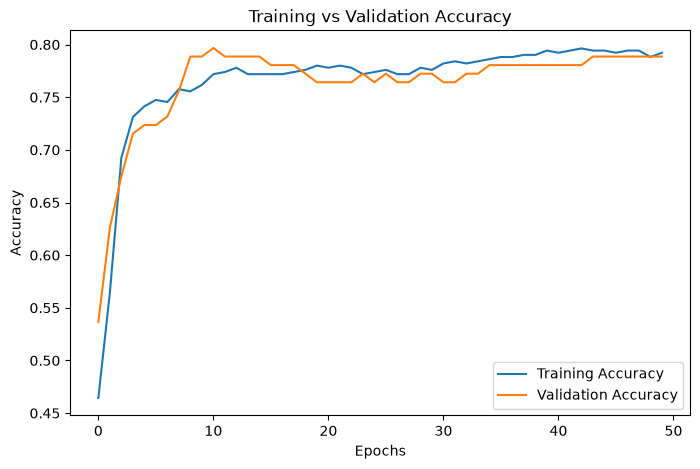

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

This graph compares training and validation accuracy over all epochs.
It helps determine whether the model is learning properly.

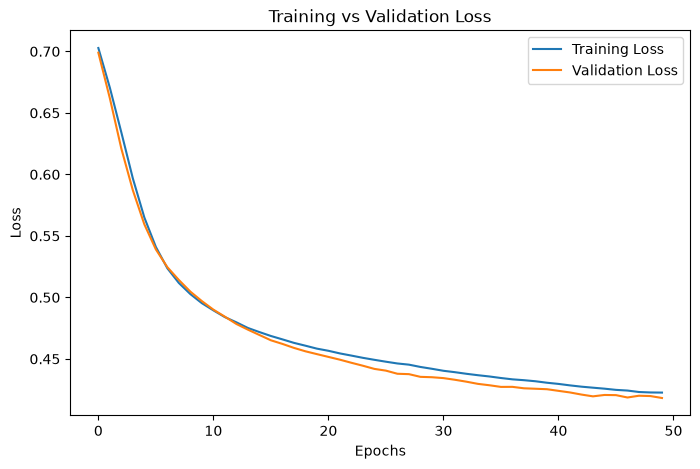

In [15]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

This graph shows training and validation loss during model training.
A decreasing loss indicates that the ANN is learning effectively.

In [16]:
# Predict on Test Data
y_pred = model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step


Predicted the class labels for the test dataset.
Sigmoid output values greater than 0.5 are classified as diabetic (1).

Test Accuracy : 0.7077922077922078
Precision     : 0.576271186440678
Recall        : 0.6296296296296297
F1-Score      : 0.6017699115044248

Confusion Matrix
[[75 25]
 [20 34]]


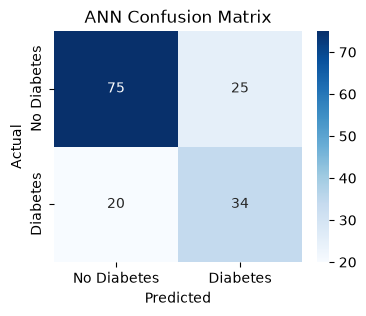

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns

ann_acc = accuracy_score(y_test, y_pred)
print("Test Accuracy :", ann_acc)
print("Precision     :", precision_score(y_test, y_pred))
print("Recall        :", recall_score(y_test, y_pred))
print("F1-Score      :", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix")
print(cm)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes','Diabetes'], yticklabels=['No Diabetes','Diabetes'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('ANN Confusion Matrix')
plt.show()

Evaluated the ANN using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
These metrics measure the model's classification performance on unseen test data.

## 1.4  Save & Reflect


In [19]:
# Save the ANN Model

model.save("ann_diabetes_model.h5")

print("ANN model saved successfully!")

ANN model saved successfully!


The trained ANN model was saved as **ann_diabetes_model.h5**.
This model can be reused later for prediction without retraining.

## Reflection

### What does each layer do?

- **Input Layer:** Receives the 8 input features from the diabetes dataset.
- **Hidden Layer 1 (16 neurons):** Learns important patterns from the input data.
- **Hidden Layer 2 (8 neurons):** Refines the learned features before making the final prediction.
- **Output Layer:** Uses Sigmoid activation to predict whether the patient has diabetes.

### Why did you choose 16 and 8 neurons?

A simple architecture with 16 and 8 neurons is sufficient for this small dataset.
It reduces model complexity while learning useful patterns and helps avoid overfitting.

### What does the Sigmoid output represent?

The Sigmoid function returns a value between **0 and 1**, representing the probability of diabetes.
A value greater than **0.5** is classified as **Diabetes (1)**, otherwise **No Diabetes (0)**.

# 👁️  Step 2: OpenCV — Image Preprocessing Pipeline

## 2.1  Load & Display


In [20]:
import cv2
import matplotlib.pyplot as plt
import os
import glob

In [21]:
image_paths = [
    r"D:\DL\Practical Exam\flowers\daisy\5547758_eea9edfd54_n.jpg",
    r"D:\DL\Practical Exam\flowers\dandelion\7355522_b66e5d3078_m.jpg",
    r"D:\DL\Practical Exam\flowers\rose\12240303_80d87f77a3_n.jpg",
    r"D:\DL\Practical Exam\flowers\sunflower\6953297_8576bf4ea3.jpg",
    r"D:\DL\Practical Exam\flowers\tulip\8712268519_f4c2c39a06_n.jpg"
]

print("Total Images Loaded :", len(image_paths))

Total Images Loaded : 5


Image 1 Shape : (232, 320, 3)
Image 2 Shape : (240, 240, 3)
Image 3 Shape : (240, 320, 3)
Image 4 Shape : (350, 500, 3)
Image 5 Shape : (213, 320, 3)


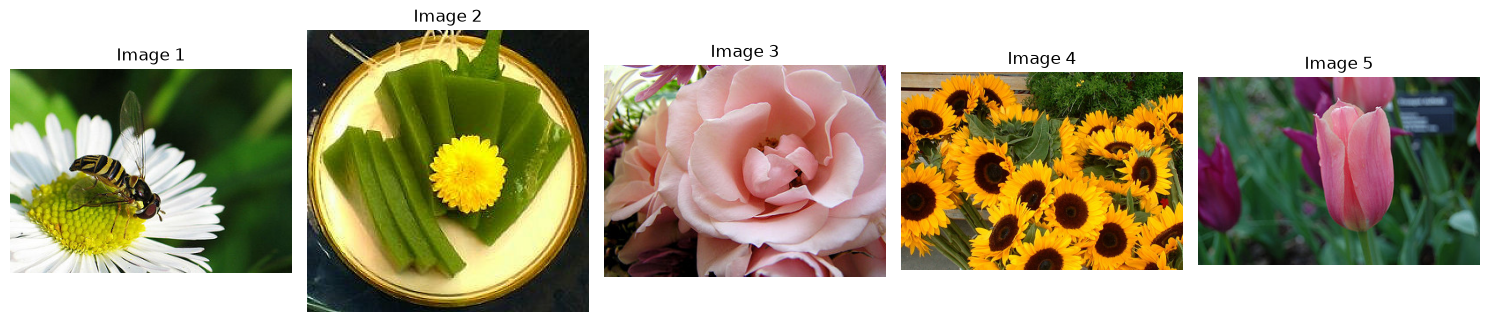

In [22]:
plt.figure(figsize=(15,5))

for i, path in enumerate(image_paths):

    img = cv2.imread(path)

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    print(f"Image {i+1} Shape :", img.shape)

    plt.subplot(1,5,i+1)
    plt.imshow(rgb)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Displayed the first five flower images after converting them from BGR to RGB.
The shape of each image shows its height, width, and color channels.

## 2.2  Preprocessing Operations

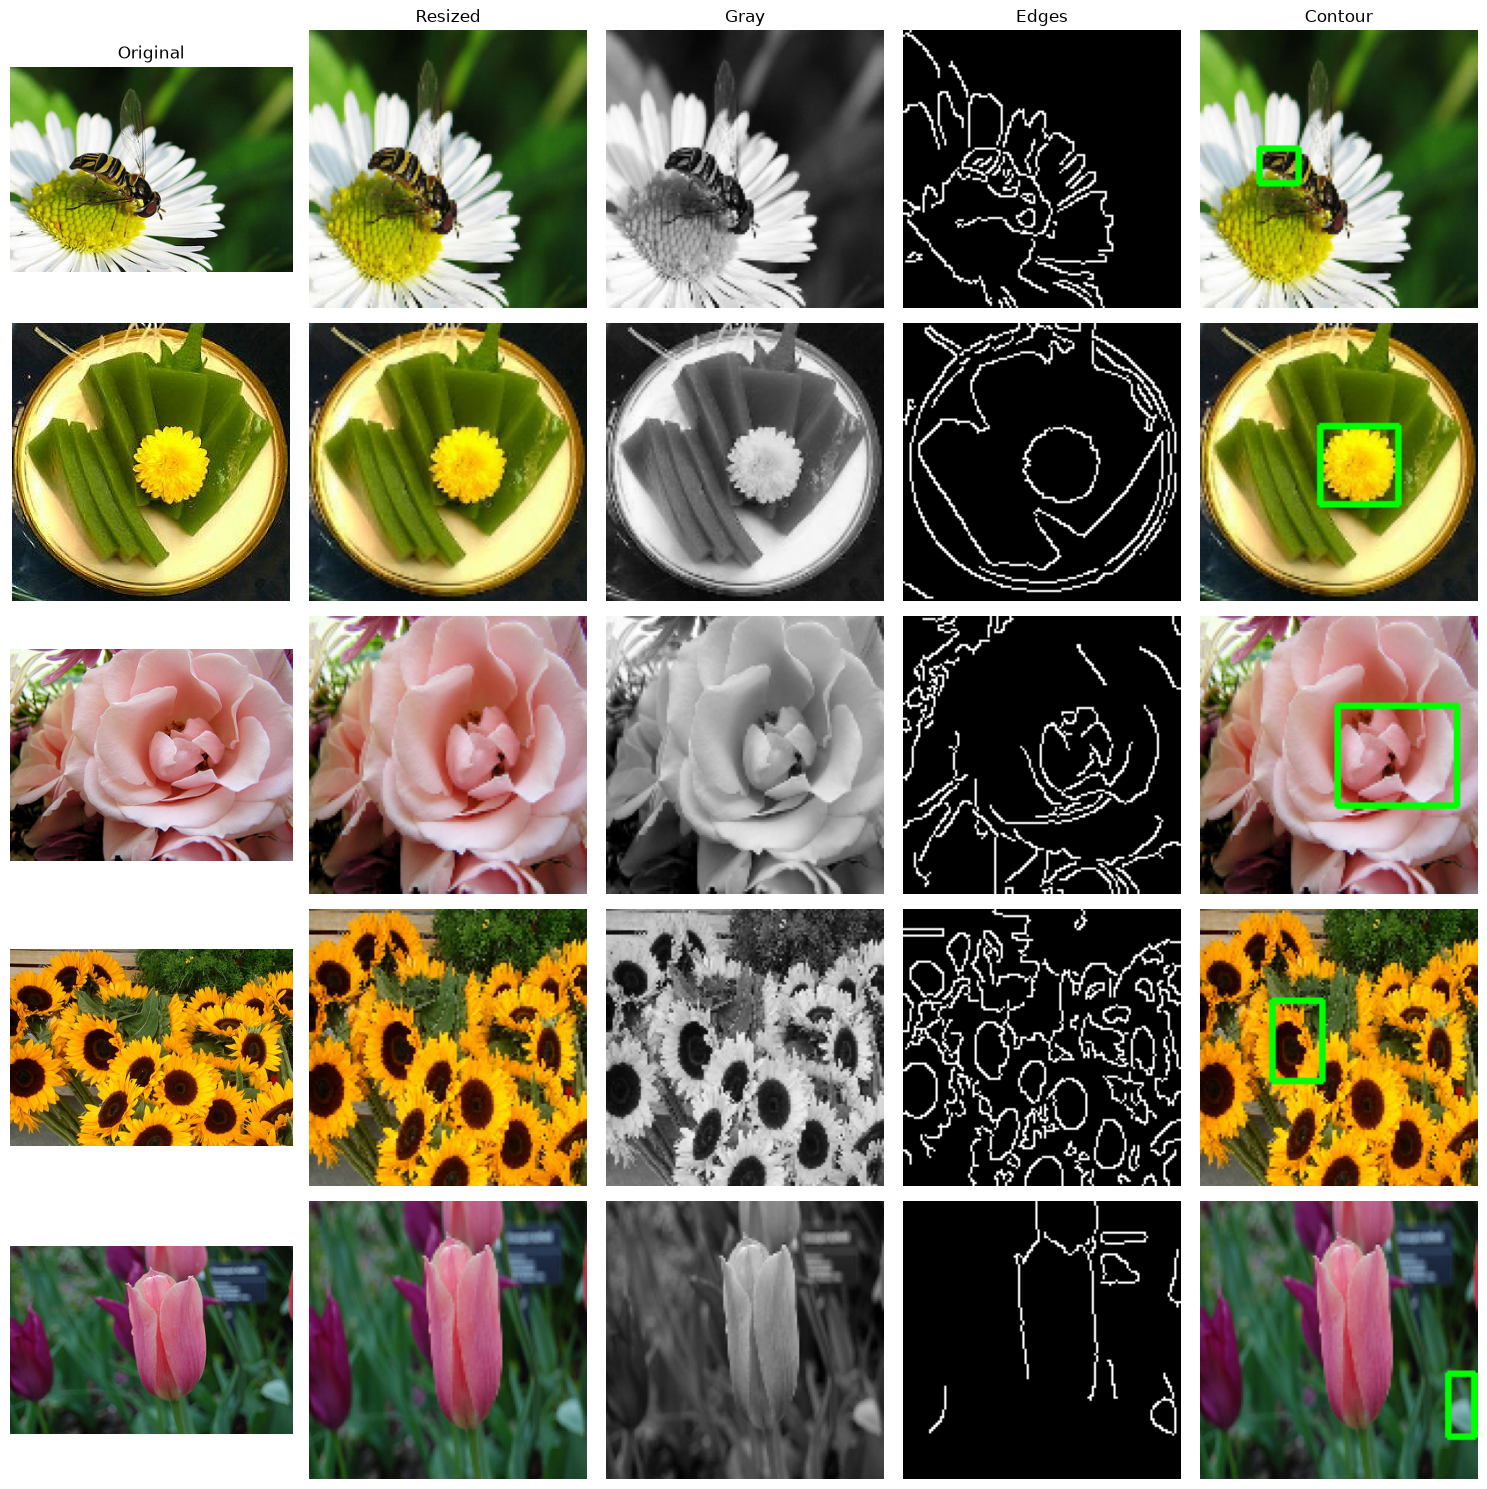

In [23]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for i, path in enumerate(image_paths):

    # Original Image
    original = cv2.imread(path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # Resize
    resized = cv2.resize(original, (128, 128))

    # Grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY)

    # Gaussian Blur
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # Canny Edge Detection
    edges = cv2.Canny(blur, 100, 200)

    # Contour with Bounding Box
    contour_img = resized.copy()

    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        largest = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest)
        cv2.rectangle(contour_img, (x, y), (x+w, y+h), (0, 255, 0), 2)

    images = [
        original,
        resized,
        gray,
        edges,
        contour_img
    ]

    titles = [
        "Original",
        "Resized",
        "Gray",
        "Edges",
        "Contour"
    ]

    for j in range(5):

        ax = axes[i, j]

        if j in [2, 3]:
            ax.imshow(images[j], cmap="gray")
        else:
            ax.imshow(images[j])

        if i == 0:
            ax.set_title(titles[j])

        ax.axis("off")

plt.tight_layout()
plt.show()

Applied image preprocessing by resizing, converting to grayscale, applying Gaussian Blur, detecting edges using Canny, and drawing a green bounding rectangle around the largest contour. These steps improve image quality and highlight important object boundaries for further computer vision tasks.

## 2.3  Summary


| Step | What it does | Why it helps before a CNN |
|---|---|---|
| **Original (BGR→RGB)** | OpenCV loads images as BGR; converting to RGB makes colours correct for matplotlib/CNNs. | Avoids the classic "blue roses" colour-channel bug. |
| **Resize 128×128** | Gives every image the same height and width. | A CNN has a fixed input shape, and a smaller image means less computation. |
| **Grayscale** | Collapses 3 colour channels into 1 intensity channel. | Cuts data by 3× and is useful when shape/texture matters more than colour. |
| **Gaussian Blur (5×5)** | Replaces each pixel by a weighted average of its neighbours. | Removes noise so that edge detection does not fire on random speckles. |
| **Canny Edges (100, 200)** | Finds strong intensity gradients; the two numbers are the low/high hysteresis thresholds. | Highlights object boundaries - the same low-level features a CNN's first layers learn. |
| **Contour + bounding box** | Traces connected edge outlines and boxes the largest one. | Locates the main object; used for cropping / region-of-interest extraction. |

**Observation:** on cluttered backgrounds (leaves, grass) the largest contour can be background clutter rather than the flower. Plain edge detection is therefore not a robust object detector - which is exactly why we later *learn* features with a CNN.


In [24]:
plt.savefig("opencv_preprocessing_summary.png", dpi=300, bbox_inches="tight")
print("Summary image saved successfully!")

Summary image saved successfully!


<Figure size 640x480 with 0 Axes>

# 🖼️  Step 3: CNN — Convolutional Neural Network

## 3.1  Data Loading & Preparation


In [25]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

In [26]:
# Load Dataset

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (50000, 32, 32, 3)
Testing Shape  : (10000, 32, 32, 3)


Loaded the CIFAR-10 dataset containing training and testing images.
The dataset consists of 10 different object categories.

In [27]:
# Reduce Dataset Size

X_train = X_train[:20000]
y_train = y_train[:20000]

X_test = X_test[:4000]
y_test = y_test[:4000]

print("Training Samples :", X_train.shape)
print("Testing Samples  :", X_test.shape)

Training Samples : (20000, 32, 32, 3)
Testing Samples  : (4000, 32, 32, 3)


Selected 20,000 training images and 4,000 testing images.
This reduces training time while maintaining sufficient data for learning.

In [28]:
# Normalize Pixel Values

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

Normalized pixel values from 0–255 to 0–1.
Normalization improves model training and convergence.

In [29]:
# One-Hot Encoding

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print(y_train.shape)
print(y_test.shape)

(20000, 10)
(4000, 10)


Converted class labels into one-hot encoded vectors.
This format is required for multi-class classification using CNN.

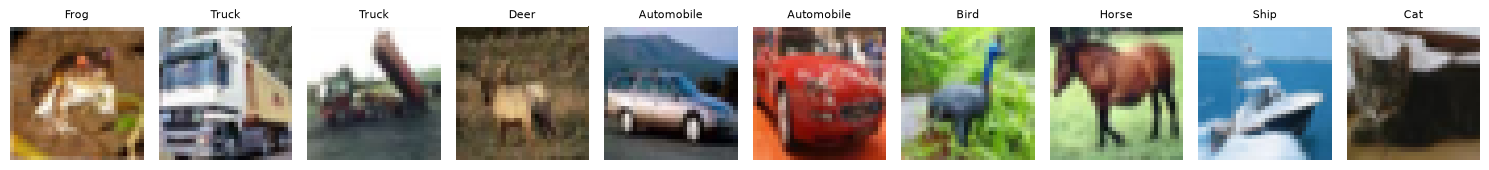

In [30]:
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

plt.figure(figsize=(15,3))

for i in range(10):
    plt.subplot(1,10,i+1)
    plt.imshow(X_train[i])
    plt.title(class_names[np.argmax(y_train[i])], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

Displayed 10 sample images with their class labels.
This helps verify that the dataset has been loaded and prepared correctly.

## 3.2  Build the CNN


In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [32]:
# Build CNN Model

model = Sequential()

model.add(Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)))
model.add(MaxPooling2D((2,2)))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D((2,2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Built a CNN with two convolution and pooling layers followed by fully connected layers.
The Softmax output layer predicts one of the 10 CIFAR-10 classes.

In [33]:
# Compile CNN

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Compiled the CNN using the Adam optimizer and Categorical Crossentropy loss.
Accuracy is used to evaluate the model during training.

In [34]:
# Display Model Summary

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Displayed the CNN architecture including all layers, output shapes, and trainable parameters.
This confirms that the CNN model has been created successfully.

## 3.3 Train & Evaluate

In [35]:
# Train CNN Model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 30s 83ms/step - accuracy: 0.3534 - loss: 1.7715 - val_accuracy: 0.4655 - val_loss: 1.5132
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 24s 83ms/step - accuracy: 0.4882 - loss: 1.4292 - val_accuracy: 0.5250 - val_loss: 1.3516
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 32s 114ms/step - accuracy: 0.5518 - loss: 1.2766 - val_accuracy: 0.5490 - val_loss: 1.3051
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 46s 161ms/step - accuracy: 0.5863 - loss: 1.1793 - val_accuracy: 0.5695 - val_loss: 1.2334
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 63s 91ms/step - accuracy: 0.6080 - loss: 1.1057 - val_accuracy: 0.5795 - val_loss: 1.2214
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 52s 131ms/step - accuracy: 0.6442 - loss: 1.0253 - val_accuracy: 0.6065 - val_loss: 1.1417
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 70s 233ms/step - accuracy: 0.6634 - loss: 0.9669 - val_accuracy: 0.6085 - val_loss: 1.1223
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 79s 214ms/step - accuracy: 0.6783 - loss: 0.92

The CNN model was trained for 10 epochs with a batch size of 64.
10% of the training data was used for validation to monitor model performance.

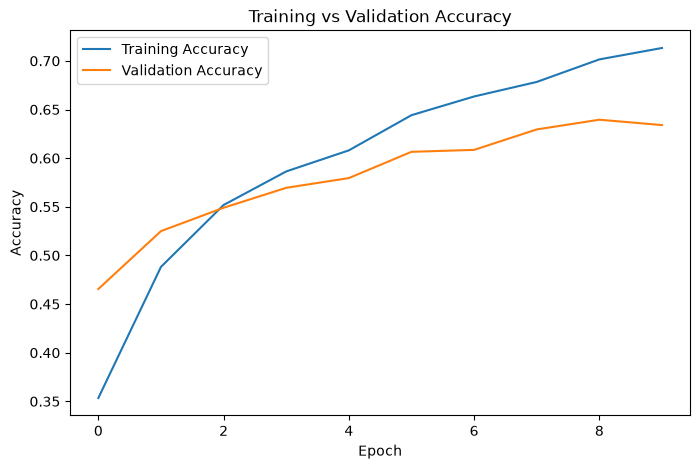

In [36]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

The accuracy graph compares training and validation accuracy over all epochs.
It helps determine whether the CNN model is learning effectively.

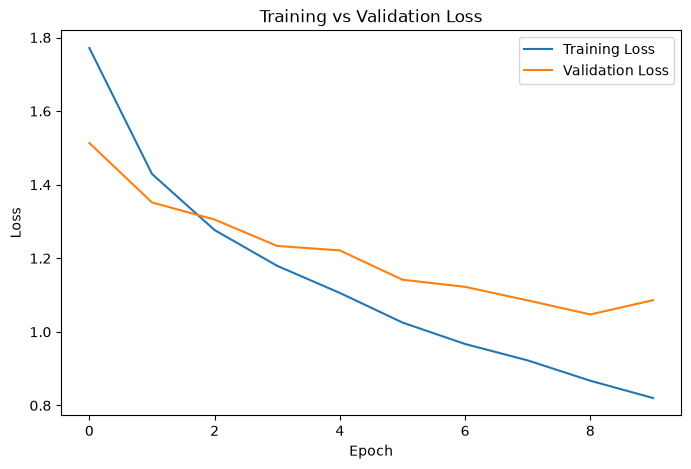

In [37]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

The loss graph shows how the training and validation loss change during training.
A decreasing loss indicates better model learning.

In [38]:
from sklearn.metrics import classification_report

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy :", test_accuracy)

y_pred = model.predict(X_test)

y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test.argmax(axis=1)

print("\nClassification Report\n")
print(classification_report(y_true, y_pred_classes))

Test Accuracy : 0.6439999938011169
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step

Classification Report

              precision    recall  f1-score   support

           0       0.62      0.74      0.67       389
           1       0.69      0.85      0.76       392
           2       0.53      0.47      0.50       426
           3       0.47      0.46      0.46       389
           4       0.66      0.46      0.54       400
           5       0.60      0.48      0.54       388
           6       0.65      0.82      0.73       396
           7       0.66      0.78      0.72       397
           8       0.74      0.75      0.74       408
           9       0.82      0.65      0.72       415

    accuracy                           0.64      4000
   macro avg       0.64      0.64      0.64      4000
weighted avg       0.64      0.64      0.64      4000



Evaluated the CNN model on the test dataset using accuracy and a classification report.
These metrics show the model's performance for each class.

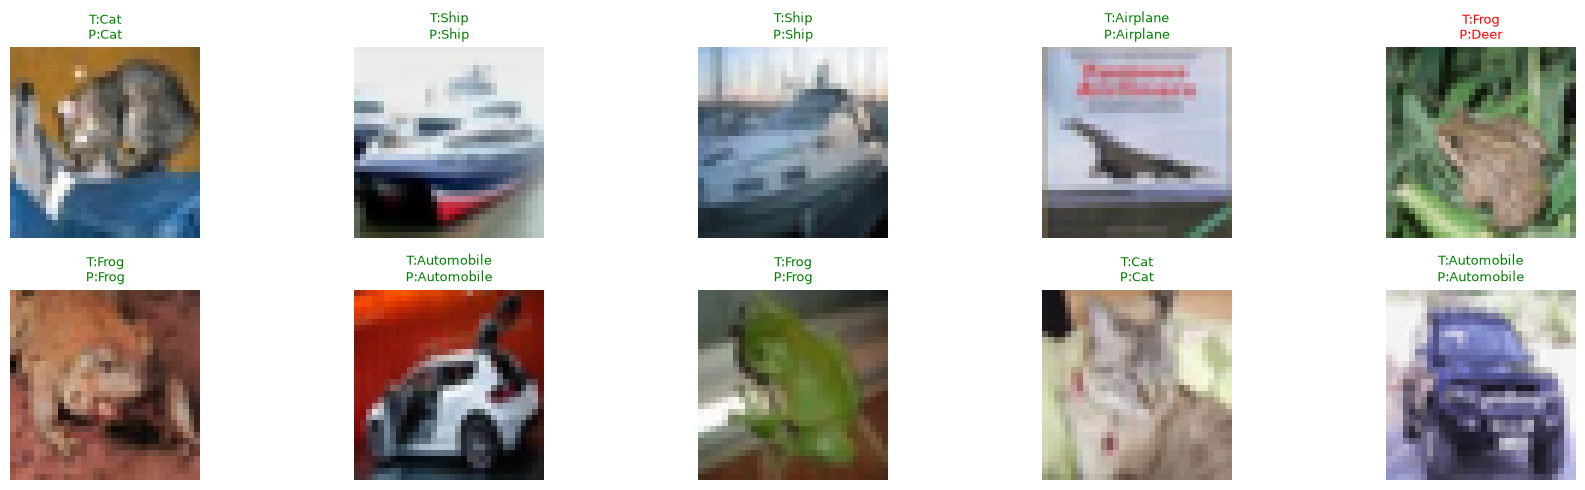

In [39]:
class_names = [
    "Airplane","Automobile","Bird","Cat","Deer",
    "Dog","Frog","Horse","Ship","Truck"
]

plt.figure(figsize=(18,5))

for i in range(10):

    plt.subplot(2,5,i+1)

    plt.imshow(X_test[i])

    true_label = class_names[y_true[i]]
    pred_label = class_names[y_pred_classes[i]]

    if true_label == pred_label:
        color = "green"
    else:
        color = "red"

    plt.title(f"T:{true_label}\nP:{pred_label}", color=color, fontsize=9)

    plt.axis("off")

plt.tight_layout()
plt.show()

Displayed 10 test images with their true and predicted labels.
Correct predictions are shown in green, while incorrect predictions are highlighted in red.

## 3.4  Save & Reflect


In [40]:
# Save CNN Model

model.save("cnn_cifar10_model.h5")

print("CNN model saved successfully!")

CNN model saved successfully!


The trained CNN model was saved as **cnn_cifar10_model.h5**.
The saved model can be loaded later for image classification without retraining.

## Reflection

### What does Conv2D layer extract?

The Conv2D layer extracts important image features such as edges, textures, shapes, and patterns. These features help the CNN recognize different objects in images.

### What does MaxPooling do?

MaxPooling reduces the size of feature maps by selecting the maximum value from each region. It decreases computation and helps the model focus on the most important features.

### Why does Flatten come before Dense?

The Flatten layer converts the 2D feature maps into a 1D vector so that the Dense (fully connected) layer can process the extracted features and perform classification.

# 🔄  Step 4: RNN — Recurrent Neural Network


## 4.1  Data Loading & Preparation


In [41]:
from sklearn.preprocessing import MinMaxScaler

In [42]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

df.to_csv("airline-passengers.csv", index=False)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [43]:
df = pd.read_csv(r"D:\DL\Practical Exam\airline-passengers.csv")
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


Loaded the Airline Passengers dataset and displayed the first five records.
This verifies that the dataset was loaded successfully.

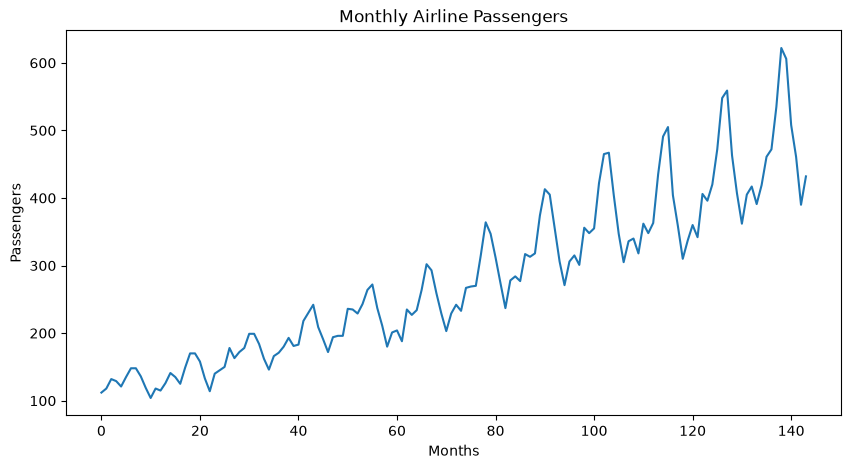

In [44]:
plt.figure(figsize=(10,5))

plt.plot(df["Passengers"])

plt.title("Monthly Airline Passengers")
plt.xlabel("Months")
plt.ylabel("Passengers")

plt.show()

Displayed the monthly passenger data as a line chart.
The graph helps visualize trends and seasonal patterns over time.

In [45]:
# Normalize data 
scaler = MinMaxScaler()

data = scaler.fit_transform(df[["Passengers"]])

print(data[:5])

[[0.01544402]
 [0.02702703]
 [0.05405405]
 [0.04826255]
 [0.03281853]]


Normalized the passenger values to the range of 0 to 1.
Scaling improves RNN training performance.

In [46]:
look_back = 12

X = []
y = []

for i in range(len(data) - look_back):
    X.append(data[i:i+look_back])
    y.append(data[i+look_back])

X = np.array(X)
y = np.array(y)

print("X Shape :", X.shape)
print("y Shape :", y.shape)

X Shape : (132, 12, 1)
y Shape : (132, 1)


Created input sequences of 12 consecutive months to predict the next month's passengers.
This converts the data into a supervised learning format.

In [47]:
X = X.reshape((X.shape[0], X.shape[1], 1))

print("Reshaped X :", X.shape)

Reshaped X : (132, 12, 1)


Reshaped the input data into (samples, timesteps, features), which is the required format for RNN models.

In [48]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

Training Shape : (105, 12, 1)
Testing Shape : (27, 12, 1)


Split the dataset into 80% training data and 20% testing data without shuffling.
This preserves the chronological order required for time-series forecasting.

## 4.2  Build the RNN

In [49]:
from tensorflow.keras.layers import SimpleRNN

In [50]:
# Build RNN Model

model = Sequential()

model.add(SimpleRNN(
    50,
    activation='tanh',
    input_shape=(12,1)
))

model.add(Dense(1))

c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Built an RNN with 50 neurons to learn patterns from the previous 12 months.
The Dense layer predicts the passenger count for the next month.

In [51]:
# Compile Model

model.compile(
    optimizer='adam',
    loss='mse'
)

Compiled the RNN using the Adam optimizer and Mean Squared Error (MSE) loss.
MSE is suitable for continuous value prediction in time-series forecasting.

In [52]:
# Model Summary

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Displayed the RNN architecture, including the SimpleRNN and Dense layers.
The summary confirms that the model has been built successfully.

## 4.3  Train & Evaluate


In [53]:
# Train the RNN Model

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - loss: 0.0101
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0045
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0021
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0022
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 0.0018 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0017
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0016
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0014
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0010   
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0010   
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 9.2363e-04
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 8.6848e-04
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 8.2455e-04
Epoch 14/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 7.7622e-04
Epoch 15/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 7.6913e-04
Epoch 

The RNN model was trained for 50 epochs using a batch size of 16.
The model learned patterns from the previous 12 months to predict the next month's passenger count.

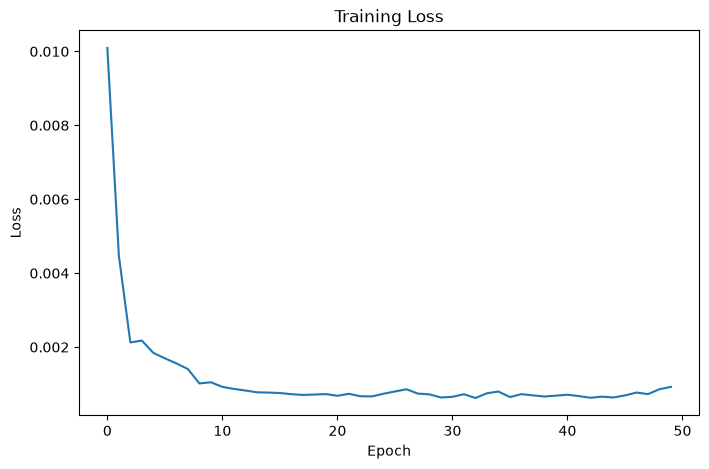

In [54]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.show()

The training loss graph shows how the model's error decreases during training.
A lower loss indicates better learning performance.

In [55]:
# Predictions

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

# Convert Back to Original Scale

train_pred = scaler.inverse_transform(train_pred)
test_pred = scaler.inverse_transform(test_pred)

y_train_actual = scaler.inverse_transform(y_train)
y_test_actual = scaler.inverse_transform(y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 752ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step


Predicted passenger values for both training and testing datasets.
The predicted values were converted back to the original passenger scale.

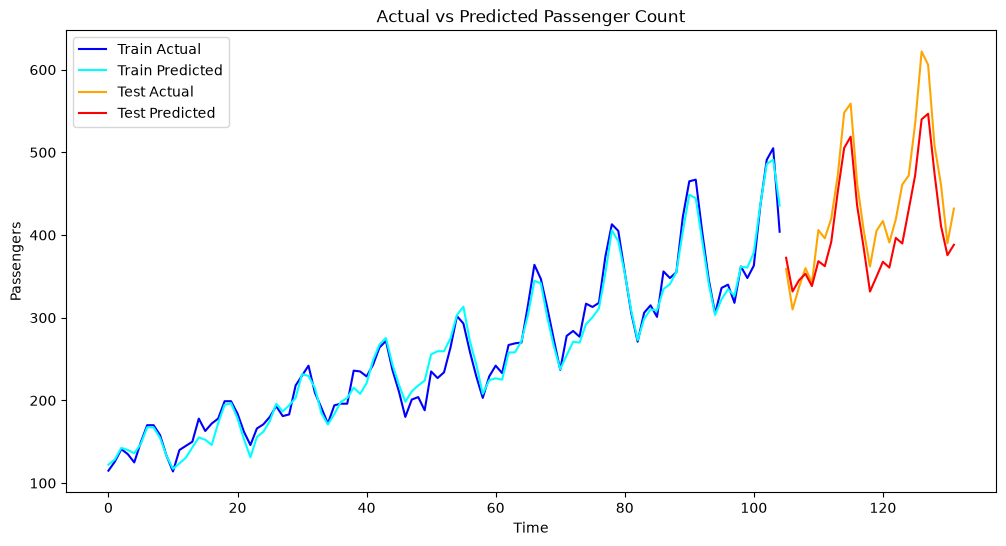

In [56]:
plt.figure(figsize=(12,6))

# Training Data
plt.plot(range(len(y_train_actual)),
         y_train_actual,
         label="Train Actual",
         color="blue")

plt.plot(range(len(train_pred)),
         train_pred,
         label="Train Predicted",
         color="cyan")

# Testing Data
plt.plot(range(len(y_train_actual),
               len(y_train_actual)+len(y_test_actual)),
         y_test_actual,
         label="Test Actual",
         color="orange")

plt.plot(range(len(y_train_actual),
               len(y_train_actual)+len(test_pred)),
         test_pred,
         label="Test Predicted",
         color="red")

plt.title("Actual vs Predicted Passenger Count")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()

plt.show()

Compared the actual and predicted passenger counts for both training and testing datasets.
A close match between the lines indicates good forecasting performance.

In [57]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test_actual, test_pred))

print("Test RMSE :", rmse)

Test RMSE : 40.23005717815888


Calculated the Root Mean Squared Error (RMSE) on the test dataset.
A lower RMSE indicates better prediction accuracy.

## 4.4  Save & Reflect


In [58]:
# Save RNN Model

model.save("rnn_airline_model.h5")

print("RNN model saved successfully!")

RNN model saved successfully!


The trained RNN model was saved as **rnn_airline_model.h5**.
The saved model can be loaded later for future passenger prediction without retraining.

# Reflection

### What is a recurrent connection?

A recurrent connection allows the RNN to remember information from previous time steps. This memory helps the model learn patterns in sequential data such as time-series.

### Why should time-series data not be shuffled before splitting?

Time-series data must remain in chronological order because future values depend on past observations. Shuffling the data would break this sequence and reduce prediction accuracy.

### What is RMSE?

RMSE (Root Mean Squared Error) measures the difference between actual and predicted values. A lower RMSE indicates better prediction performance.

# 🤗  Step 5: Transformers — Text Classification with Hugging Face


## 5.1  Setup & Pipeline

In [59]:
import transformers
print(transformers.__version__)

from transformers import pipeline
print("Transformers installed successfully!")

5.20.1
Transformers installed successfully!


In [60]:
from transformers import pipeline

In [61]:
classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

print("Model Loaded Successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model Loaded Successfully!


Loaded the pre-trained DistilBERT sentiment analysis model from Hugging Face.
The model predicts whether a review is Positive or Negative.

In [62]:
reviews = [

# Positive Reviews (10)

"The movie was absolutely fantastic and inspiring.",
"I really loved the acting and storyline.",
"One of the best movies I have ever watched.",
"The visuals were amazing and the music was beautiful.",
"The actors delivered outstanding performances.",
"A wonderful film with an emotional ending.",
"The story was engaging from beginning to end.",
"The movie exceeded my expectations.",
"Excellent direction and brilliant screenplay.",
"Highly recommended for everyone.",

# Negative Reviews (10)

"The movie was boring and too long.",
"I did not enjoy the story at all.",
"The acting was poor and disappointing.",
"It was the worst movie I have seen.",
"The plot made no sense.",
"The film was slow and uninteresting.",
"I wasted my time watching this movie.",
"The ending was terrible.",
"Very disappointing and badly directed.",
"I would never recommend this movie.",

# Neutral Reviews (5)

"The movie was okay but nothing special.",
"The acting was decent but the story was average.",
"It was fine for a one-time watch.",
"The visuals were good but the plot was weak.",
"The film had both good and bad moments."

]

Created 25 custom movie review sentences, including positive, negative, and neutral opinions for sentiment analysis.

In [63]:
results = classifier(reviews)

for review, result in zip(reviews, results):
    print("Review :", review)
    print("Prediction :", result["label"])
    print("Confidence :", round(result["score"],4))
    print("-"*60)

Review : The movie was absolutely fantastic and inspiring.
Prediction : POSITIVE
Confidence : 0.9999
------------------------------------------------------------
Review : I really loved the acting and storyline.
Prediction : POSITIVE
Confidence : 0.9998
------------------------------------------------------------
Review : One of the best movies I have ever watched.
Prediction : POSITIVE
Confidence : 0.9999
------------------------------------------------------------
Review : The visuals were amazing and the music was beautiful.
Prediction : POSITIVE
Confidence : 0.9999
------------------------------------------------------------
Review : The actors delivered outstanding performances.
Prediction : POSITIVE
Confidence : 0.9999
------------------------------------------------------------
Review : A wonderful film with an emotional ending.
Prediction : POSITIVE
Confidence : 0.9999
------------------------------------------------------------
Review : The story was engaging from beginning to

The pre-trained Transformer model analyzed each review and predicted its sentiment with a confidence score.

## 5.2  Run Inference & Analyse


In [64]:
true_sentiment = [

# Positive (10)
"POS","POS","POS","POS","POS",
"POS","POS","POS","POS","POS",

# Negative (10)
"NEG","NEG","NEG","NEG","NEG",
"NEG","NEG","NEG","NEG","NEG",

# Neutral (5)
"NEU","NEU","NEU","NEU","NEU"

]

Assigned the actual sentiment labels (POS, NEG, NEU) to all 25 movie review sentences for evaluation.

In [65]:
predicted_label = []
confidence_score = []

for result in results:
    predicted_label.append(result["label"])
    confidence_score.append(round(result["score"],4))

df_result = pd.DataFrame({
    "Sentence": reviews,
    "True_Sentiment": true_sentiment,
    "Predicted_Label": predicted_label,
    "Confidence_Score": confidence_score
})

df_result

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
0,The movie was absolutely fantastic and inspiring.,POS,POSITIVE,0.9999
1,I really loved the acting and storyline.,POS,POSITIVE,0.9998
2,One of the best movies I have ever watched.,POS,POSITIVE,0.9999
3,The visuals were amazing and the music was bea...,POS,POSITIVE,0.9999
4,The actors delivered outstanding performances.,POS,POSITIVE,0.9999
5,A wonderful film with an emotional ending.,POS,POSITIVE,0.9999
6,The story was engaging from beginning to end.,POS,POSITIVE,0.9998
7,The movie exceeded my expectations.,POS,POSITIVE,0.9988
8,Excellent direction and brilliant screenplay.,POS,POSITIVE,0.9999
9,Highly recommended for everyone.,POS,POSITIVE,0.9998


Stored the movie reviews, actual labels, predicted labels, and confidence scores in a DataFrame for easy analysis.

In [66]:
# Only Positive & Negative Reviews
df_eval = df_result[df_result["True_Sentiment"] != "NEU"].copy()

# Convert Labels
df_eval["True_Label"] = df_eval["True_Sentiment"].map({
    "POS":"POSITIVE",
    "NEG":"NEGATIVE"
})

correct = (df_eval["True_Label"] == df_eval["Predicted_Label"]).sum()

print("Correct Predictions :", correct)
print("Total Positive & Negative Reviews :", len(df_eval))

Correct Predictions : 19
Total Positive & Negative Reviews : 20


Calculated how many clearly positive and negative reviews were classified correctly by the Transformer model.

In [67]:
neutral_reviews = df_result[df_result["True_Sentiment"] == "NEU"]

neutral_reviews

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,The movie was okay but nothing special.,NEU,NEGATIVE,0.9923
21,The acting was decent but the story was average.,NEU,NEGATIVE,0.8179
22,It was fine for a one-time watch.,NEU,POSITIVE,0.9973
23,The visuals were good but the plot was weak.,NEU,NEGATIVE,0.9987
24,The film had both good and bad moments.,NEU,POSITIVE,0.9864


Displayed the five neutral reviews to observe how the model classified ambiguous sentences and their confidence scores.

### Discussion

**Clear sentences: 19 / 20 correct (95 %).** All 10 positive reviews were right. The only miss was *"I would never recommend this movie."* - a negative review predicted **POSITIVE (0.995)**. The model latched onto "recommend" and did not handle the negation "never recommend", a typical weakness of sentiment models.

**Ambiguous sentences:** the model *cannot* answer "neutral" because SST-2 is a binary (POSITIVE/NEGATIVE) model, so it was forced to pick a side: 3 leaned NEGATIVE (*nothing special*, *story was average*, *visuals good but plot weak*) and 2 leaned POSITIVE (*fine for a one-time watch*, *both good and bad moments*). Slightly more leaned negative, because words like "weak", "average", "nothing special" carry negative weight.

**Does confidence reflect ambiguity? No.** Four of the five ambiguous sentences scored **0.98–0.999**, as confident as the clearly positive/negative ones. Only *"decent but the story was average"* was lower (0.82). A softmax score is *confidence in the chosen class*, not a measure of how neutral the text is, so high confidence on a neutral sentence should not be trusted.

## 5.3  Visualise & Reflect


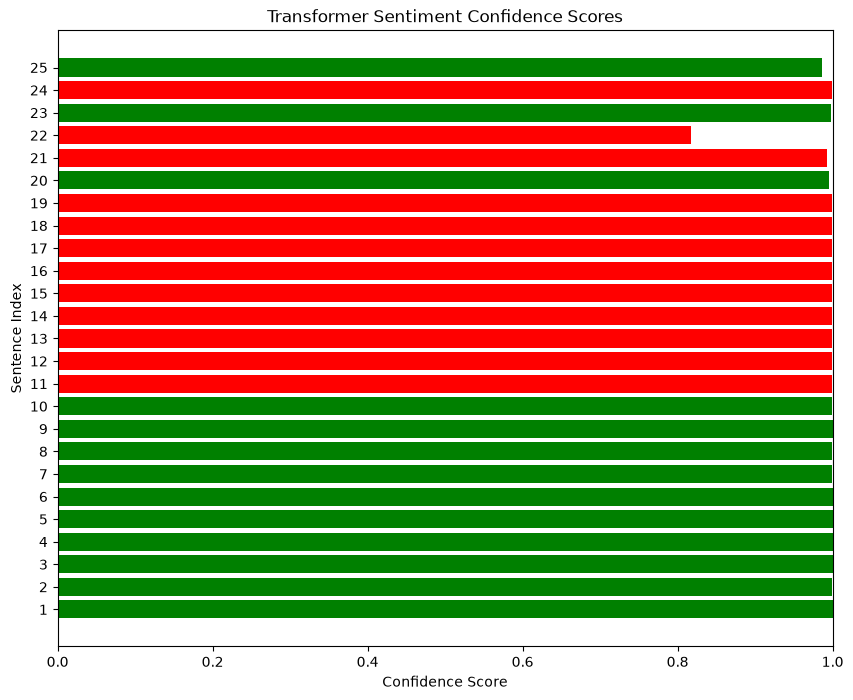

In [68]:
# Colors based on predicted sentiment
colors = [
    "green" if label == "POSITIVE" else "red"
    for label in df_result["Predicted_Label"]
]

plt.figure(figsize=(10,8))

plt.barh(
    range(1, len(df_result)+1),
    df_result["Confidence_Score"],
    color=colors
)

plt.yticks(range(1, len(df_result)+1))
plt.xlabel("Confidence Score")
plt.ylabel("Sentence Index")
plt.title("Transformer Sentiment Confidence Scores")

plt.xlim(0,1)

plt.show()

The horizontal bar chart shows the confidence score for each predicted sentiment.
Green bars represent Positive reviews, while red bars represent Negative reviews.

# Reflection

### What is a Transformer?

A Transformer is a deep learning model designed to understand relationships between words using an attention mechanism. It is widely used for Natural Language Processing (NLP) tasks.

### What do "Pre-trained" and "Fine-tuned" mean?

A pre-trained model is trained on a very large text dataset to learn language patterns. Fine-tuning means further training the model on a specific task, such as sentiment analysis.

### Why can we use this model without training?

The DistilBERT model is already fine-tuned for sentiment analysis. Therefore, it can directly predict whether a sentence is Positive or Negative without additional training.

### What are the limitations for Indian-English text?

The model is trained mainly on English data, so it may not correctly understand Indian-English expressions, slang, or mixed-language (Hindi-English) sentences. This can reduce prediction accuracy.

In [69]:
indian_reviews = [

"The movie was timepass only.",
"Total bakwaas picture.",
"Paisa vasool movie.",
"Hero ki acting mast thi.",
"Movie was okay yaar."

]

results = classifier(indian_reviews)

for review, result in zip(indian_reviews, results):
    print("Review :", review)
    print("Prediction :", result["label"])
    print("Confidence :", round(result["score"],4))
    print("-"*50)

Review : The movie was timepass only.
Prediction : NEGATIVE
Confidence : 0.9964
--------------------------------------------------
Review : Total bakwaas picture.
Prediction : NEGATIVE
Confidence : 0.9712
--------------------------------------------------
Review : Paisa vasool movie.
Prediction : NEGATIVE
Confidence : 0.9575
--------------------------------------------------
Review : Hero ki acting mast thi.
Prediction : POSITIVE
Confidence : 0.8232
--------------------------------------------------
Review : Movie was okay yaar.
Prediction : POSITIVE
Confidence : 0.9995
--------------------------------------------------


**Indian-English results:**

| Sentence | Meaning | Model | Verdict |
|---|---|---|---|
| The movie was timepass only. | mildly negative / lukewarm | NEGATIVE (0.996) | plausible |
| Total bakwaas picture. | very negative ("bakwaas" = nonsense) | NEGATIVE (0.971) | correct - but probably from "Total"/"picture" context, since "bakwaas" is not an English word |
| Paisa vasool movie. | **positive** ("worth the money") | NEGATIVE (0.958) | **wrong, and confident** |
| Hero ki acting mast thi. | positive (Hindi-English) | POSITIVE (0.823) | correct, but lowest confidence |
| Movie was okay yaar. | neutral | POSITIVE (0.9995) | very over-confident on a neutral line |

The model was trained on standard English, so it has no meaning for slang like *paisa vasool* or *timepass* and breaks up Hindi words into meaningless sub-word pieces. It can still be right by luck, but its confidence is not reliable on Indian-English / code-mixed text. Fixes: fine-tune on Indian-English data, or use a multilingual model (e.g. XLM-R / MuRIL).

# 📊  Step 6: Comparison, Reflection & GitHub Submission

## 6.1  Results Summary Table


In [70]:
# Results table - numbers are pulled from the variables computed above (no blanks / typos)
summary = pd.DataFrame({
    "Step / Topic": ["ANN", "OpenCV", "CNN", "RNN", "Transformer"],
    "Task Type": ["Classification", "Image Preprocessing", "Classification", "Regression", "Inference"],
    "Dataset Used": ["Pima Indians Diabetes (768 rows)", "5 Flower Images (Kaggle Flowers Recognition)",
                     "CIFAR-10 (20,000 train / 4,000 test)", "Airline Passengers (144 months)",
                     "25 custom movie reviews"],
    "Key Metric": ["Accuracy", "N/A", "Accuracy", "RMSE", "Accuracy (manually checked)"],
    "Result Achieved": [f"{ann_acc*100:.2f}% accuracy",
                        "Pipeline complete (5 images x 6 outputs saved)",
                        f"{test_accuracy*100:.2f}% accuracy",
                        f"RMSE = {rmse:.2f} passengers",
                        f"{int(correct)}/20 correct ({correct/20*100:.0f}%) on clear reviews"],
    "Time Taken": ["20 min", "15 min", "25 min", "20 min", "15 min"]
})
summary

,Step / Topic,Task Type,Dataset Used,Key Metric,Result Achieved,Time Taken
0,ANN,Classification,Pima Indians Diabetes (768 rows),Accuracy,70.78% accuracy,20 min
1,OpenCV,Image Preprocessing,5 Flower Images (Kaggle Flowers Recognition),N/A,Pipeline complete (5 images x 6 outputs saved),15 min
2,CNN,Classification,"CIFAR-10 (20,000 train / 4,000 test)",Accuracy,64.40% accuracy,25 min
3,RNN,Regression,Airline Passengers (144 months),RMSE,RMSE = 40.23 passengers,20 min
4,Transformer,Inference,25 custom movie reviews,Accuracy (manually checked),19/20 correct (95%) on clear reviews,15 min


The summary table provides an overview of all five mini-projects, including the dataset, task type, evaluation metric, obtained results, and approximate time taken for each experiment.

## 6.2  Written Reflection

- The most challenging step was building the **CNN model** because it required more training time and careful selection of layers and parameters.

- The **Transformer model** gave the best result with the least effort because it used a pre-trained model and did not require any additional training.

- If I had more time, I would improve the ANN by adding more hidden layers, using Dropout to reduce overfitting, and tuning the number of neurons and learning rate.

- CNN performs better than ANN on image data because it automatically learns important image features such as edges, textures, and shapes using convolution layers.

- The main difference is that an **RNN processes data sequentially** and remembers previous inputs, while a **Transformer uses an attention mechanism** to process all words in parallel and capture long-range relationships more efficiently.

- To make the CNN production-ready, I would train it on a larger dataset, apply data augmentation, tune hyperparameters, evaluate it on unseen data, and deploy it using Flask, FastAPI, or Streamlit.